# EDA: дневные снятия по филиалам

Работаем с `data/daily.parquet` (результат `src/build_daily.py`) и тремя оставшимися файлами.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 70)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams["figure.figsize"] = (12, 3.5)

DATA = "../data"
daily = pd.read_parquet(f"{DATA}/daily.parquet")
daily["date"] = pd.to_datetime(daily["date"])
branches = pd.read_csv(f"{DATA}/branches.csv", parse_dates=["open_date"])
cash = pd.read_csv(f"{DATA}/cash_ops.csv", parse_dates=["date"])
template = pd.read_csv(f"{DATA}/submission_template.csv", parse_dates=["date"])

target = (
    daily[daily["txn_type"] == "withdrawal"]
    .groupby(["branch_id", "date"], as_index=False)["amount_uzs"].sum()
    .rename(columns={"amount_uzs": "y"})
)
HIST_END = target["date"].max()
print("строк:", len(target), "| период:", target["date"].min().date(), "-", HIST_END.date())

строк: 71673 | период: 2023-01-01 - 2026-05-10


## 1. Какие филиалы прогнозируем

In [2]:
print("шаблон:", template["branch_id"].nunique(), "филиалов,",
      template["date"].min().date(), "-", template["date"].max().date(), "|", len(template), "строк")

span = target.groupby("branch_id").agg(
    first=("date", "min"), last=("date", "max"), n_days=("date", "nunique"), mean_y=("y", "mean")
)
span = span.join(branches.set_index("branch_id"))
span["in_template"] = span.index.isin(template["branch_id"].unique())

print("\nФилиалы, которых нет в шаблоне:")
display(span[~span["in_template"]])
print("Филиалы шаблона, которых нет в транзакциях:",
      sorted(set(template["branch_id"]) - set(span.index)))

шаблон: 59 филиалов, 2026-05-11 - 2026-06-09 | 1770 строк

Филиалы, которых нет в шаблоне:


,first,last,n_days,mean_y,region,branch_type,open_date,in_template
branch_id,,,,,,,,
B017,2023-01-01,2025-06-30,912,"1,464,397,329.002",Toshkent vil.,filial,2013-02-01,False


Филиалы шаблона, которых нет в транзакциях: []


In [3]:
print("Раньше всех заканчиваются:")
display(span.sort_values("last").head(5)[["first", "last", "n_days", "open_date", "in_template"]])
print("Позже всех начинаются:")
display(span.sort_values("first").tail(5)[["first", "last", "n_days", "open_date", "in_template"]])

Раньше всех заканчиваются:


,first,last,n_days,open_date,in_template
branch_id,,,,,
B017,2023-01-01,2025-06-30,912,2013-02-01,False
B001,2023-01-01,2026-05-10,1226,2017-03-01,True
B033,2024-03-01,2026-05-10,801,2024-03-01,True
B034,2023-01-01,2026-05-10,1226,2021-06-01,True
B035,2023-01-01,2026-05-10,1226,2018-12-01,True


Позже всех начинаются:


,first,last,n_days,open_date,in_template
branch_id,,,,,
B026,2023-01-01,2026-05-10,1226,2019-08-01,True
B027,2023-01-01,2026-05-10,1226,2012-10-01,True
B029,2023-01-01,2026-05-10,1226,2014-11-01,True
B033,2024-03-01,2026-05-10,801,2024-03-01,True
B060,2026-02-02,2026-05-10,98,2026-02-02,True


**Вывод.** В шаблоне 59 филиалов из 60. B017 (Toshkent vil., filial, в среднем 1,46 млрд сум в день) закрыт:
последний день с операциями 30.06.2025, прогноз по нему не нужен. B060 открыт 02.02.2026 (98 дней истории),
B033 открыт 01.03.2024 (801 день). У остальных 57 филиалов история полная, 1226 дней.

## 2. Дыры в рядах

День без единого снятия в `daily.parquet` просто отсутствует. Нужно понять, это ноль или филиал не работал.

In [4]:
# полная сетка: каждый филиал x каждый день от его первой до последней даты
grid = pd.concat(
    pd.DataFrame({"branch_id": b, "date": pd.date_range(r["first"], r["last"])})
    for b, r in span.iterrows()
)
full = grid.merge(target, on=["branch_id", "date"], how="left")
miss = full[full["y"].isna()]

print(f"дней в сетке: {len(full)}, без снятий: {len(miss)} ({len(miss) / len(full):.2%})")
print("\nПо дням недели:")
print(miss["date"].dt.day_name().value_counts())

дней в сетке: 71693, без снятий: 20 (0.03%)

По дням недели:
date
Monday       4
Tuesday      4
Wednesday    4
Thursday     4
Friday       4
Name: count, dtype: int64


In [5]:
print("Даты, когда снятий не было сразу во многих филиалах:")
display(miss.groupby("date").size().sort_values(ascending=False).head(15).to_frame("филиалов без снятий"))

per_branch = miss.groupby("branch_id").size().reindex(span.index, fill_value=0)
longest = target.sort_values("date").groupby("branch_id")["date"].apply(
    lambda d: int(d.diff().dt.days.max() - 1) if len(d) > 1 else 0
)
gaps = pd.DataFrame({"пропущено дней": per_branch, "самая длинная дыра": longest})
print("Филиалы с наибольшим числом пропусков:")
display(gaps.sort_values("пропущено дней", ascending=False).head(10))

Даты, когда снятий не было сразу во многих филиалах:


,филиалов без снятий
date,
2025-11-10,4
2025-11-11,4
2025-11-12,4
2025-11-13,4
2025-11-14,4


Филиалы с наибольшим числом пропусков:


,пропущено дней,самая длинная дыра
branch_id,,
B051,5,5
B052,5,5
B054,5,5
B053,5,5
B005,0,0
B006,0,0
B007,0,0
B008,0,0
B001,0,0


**Вывод.** Пропусков всего 20 из 71 693 дней: филиалы B051-B054 (все четыре из Xorazm), 10-14 ноября 2025, пн-пт.
Это региональный сбой, а не нулевой спрос. В обучении эти дни считаем пропуском и нулями не заполняем.


## 3. Сезонность и тренд

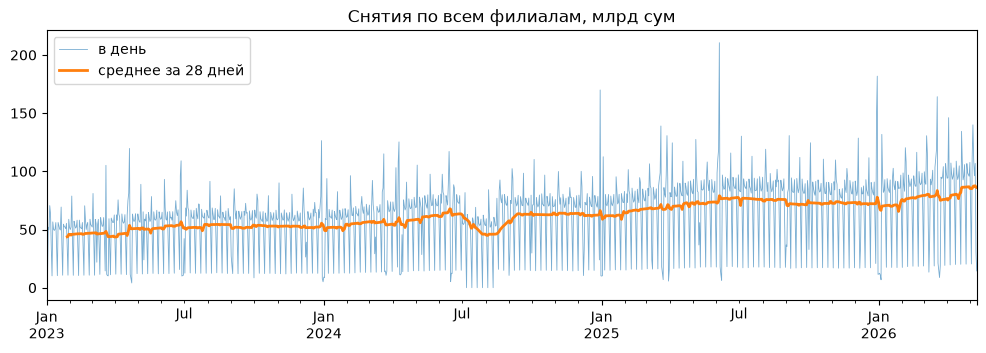

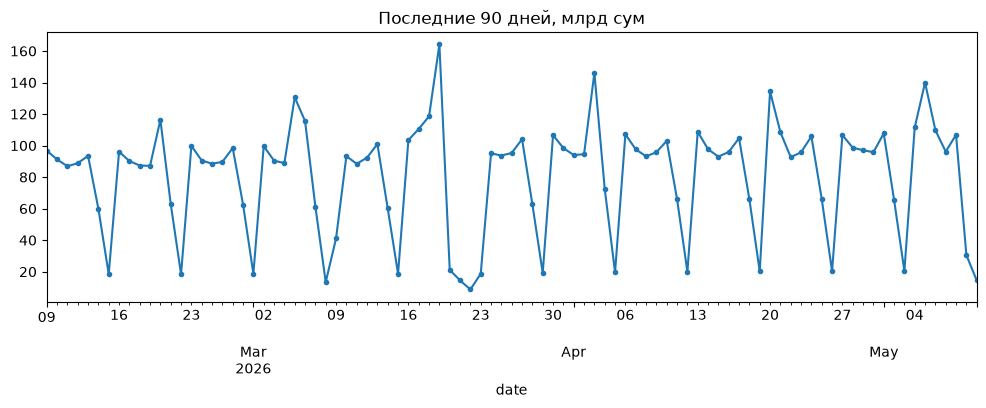

In [6]:
total = full.fillna({"y": 0}).groupby("date")["y"].sum() / 1e9  # млрд сум

ax = total.plot(lw=0.6, alpha=0.6, label="в день")
total.rolling(28).mean().plot(ax=ax, lw=2, label="среднее за 28 дней")
ax.set(title="Снятия по всем филиалам, млрд сум", xlabel="")
ax.legend()
plt.show()

total.loc[HIST_END - pd.Timedelta(days=90):].plot(marker="o", ms=3, title="Последние 90 дней, млрд сум")
plt.show()

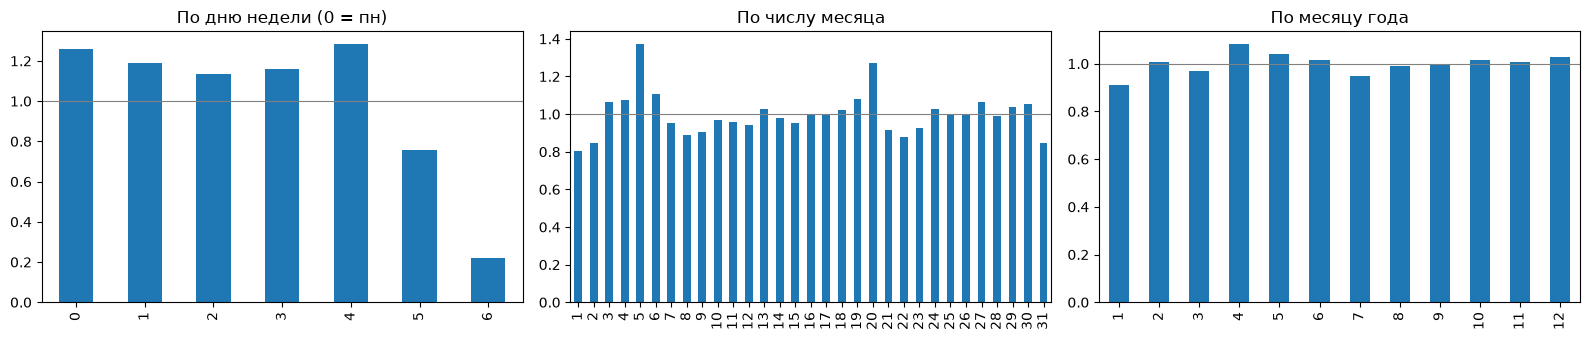

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
rel = total / total.mean()

rel.groupby(rel.index.day_of_week).mean().plot.bar(ax=axes[0], title="По дню недели (0 = пн)")
rel.groupby(rel.index.day).mean().plot.bar(ax=axes[1], title="По числу месяца")
rel.groupby(rel.index.month).mean().plot.bar(ax=axes[2], title="По месяцу года")
for ax in axes:
    ax.axhline(1, color="gray", lw=0.8)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [8]:
# Аномальные дни. Сравниваем день с медианой ТОГО ЖЕ дня недели за +-4 недели,
# иначе в списке окажутся одни воскресенья.
same_wd = total.groupby(total.index.day_of_week).transform(
    lambda s: s.rolling(9, center=True, min_periods=5).median()
)
ratio = (total / same_wd.where(same_wd > 0)).dropna()

def show(days):
    return pd.DataFrame({
        "отношение к норме": days.round(2),
        "день недели": days.index.day_name(),
        "число месяца": days.index.day,
    })

print("Самые низкие дни (праздники, сбои):")
display(show(ratio.sort_values().head(25)))
print("Самые высокие дни (канун праздников, зарплата):")
display(show(ratio.sort_values(ascending=False).head(25)))

Самые низкие дни (праздники, сбои):


,отношение к норме,день недели,число месяца
date,,,
2023-01-02,0.130,Monday,2
2026-01-02,0.130,Friday,2
2024-01-01,0.140,Monday,1
2024-12-31,0.140,Tuesday,31
2024-01-02,0.140,Tuesday,2
2025-12-31,0.140,Wednesday,31
2025-01-02,0.140,Thursday,2
2025-01-01,0.140,Wednesday,1
2026-01-01,0.140,Thursday,1


Самые высокие дни (канун праздников, зарплата):


,отношение к норме,день недели,число месяца
date,,,
2024-06-30,2.890,Sunday,30
2025-06-05,2.530,Thursday,5
2024-12-30,2.140,Monday,30
2025-12-30,2.110,Tuesday,30
2023-04-20,2.080,Thursday,20
2023-12-29,1.890,Friday,29
2024-06-15,1.830,Saturday,15
2024-04-09,1.780,Tuesday,9
2023-06-27,1.770,Tuesday,27


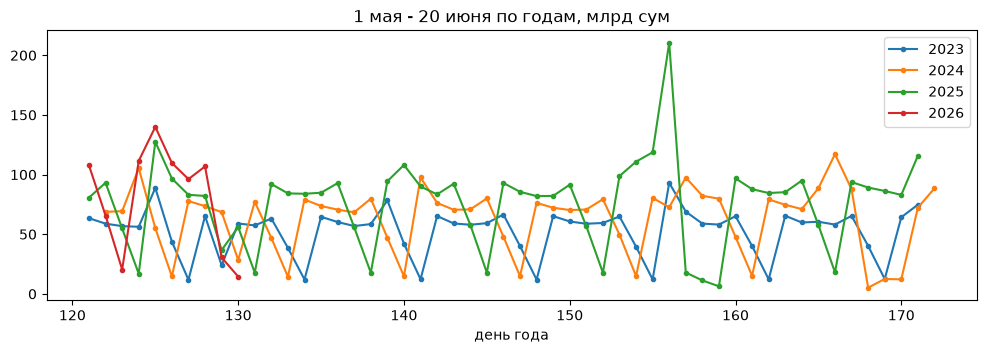

In [9]:
# То же окно, что в прогнозе (11 мая - 9 июня), в прошлые годы
fig, ax = plt.subplots()
for year in sorted(total.index.year.unique()):
    win = total.loc[f"{year}-05-01":f"{year}-06-20"]
    if len(win):
        ax.plot(win.index.day_of_year, win.values, marker="o", ms=3, label=str(year))
ax.set(title="1 мая - 20 июня по годам, млрд сум", xlabel="день года")
ax.legend()
plt.show()

Доля в сумме снятий:


,доля
channel,
ATM,0.295
KASSA,0.705


,доля
client_segment,
payroll,0.125
premium,0.030
retail,0.775
sme,0.070


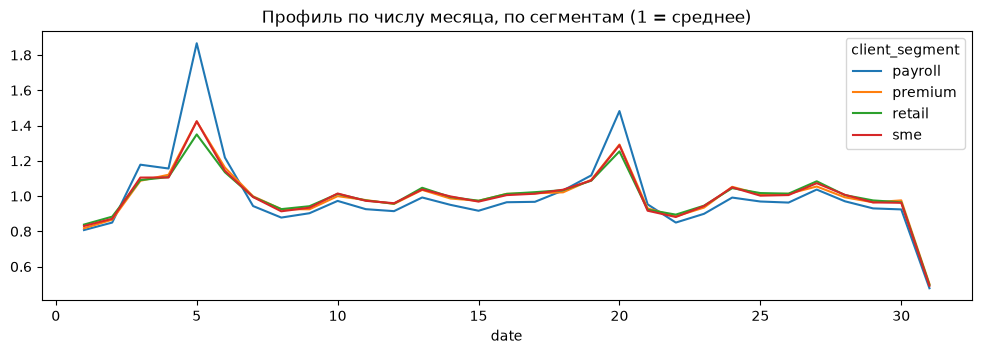

In [10]:
# Каналы и сегменты: доля в сумме снятий и профиль по числу месяца
w = daily[daily["txn_type"] == "withdrawal"]
print("Доля в сумме снятий:")
display((w.groupby("channel")["amount_uzs"].sum() / w["amount_uzs"].sum()).to_frame("доля"))
display((w.groupby("client_segment")["amount_uzs"].sum() / w["amount_uzs"].sum()).to_frame("доля"))

seg = w.groupby([w["date"].dt.day, "client_segment"])["amount_uzs"].sum().unstack()
(seg / seg.mean()).plot(title="Профиль по числу месяца, по сегментам (1 = среднее)")
plt.show()

**Вывод.**
- **Тренд.** Снятия выросли с ~45 до ~87 млрд сум в день за 3,4 года. Уровень надо брать из последних месяцев.
- **Неделя** - самый сильный фактор: пн и пт на 26-28% выше среднего, сб 0,76, вс 0,22.
- **Зарплатные дни.** 5-е число x1,37, 20-е x1,27; у сегмента payroll пик x1,87. Если дата выпадает на выходной,
  пик сдвигается на пятницу (3 апреля 2026 вместо 5-го).
- **Праздники.** Накануне всплеск, в праздник провал. 5 июня 2025 - x2,5: канун Курбан хайита совпал с зарплатой.
  Даты хайитов сдвигаются каждый год, номером дня в году их не описать - нужен календарь.
- **Месяц года** влияет слабо (0,91-1,08).
- **Каналы.** Касса даёт 70,5% суммы снятий, банкоматы 29,5%, хотя по числу операций банкоматов больше.
- **В окно прогноза (11 мая - 9 июня 2026) попадают:** зарплата 20 мая, Курбан хайит (около 27 мая), зарплата 5 июня.
- **Аномалия.** В июле-августе 2024 уровень падает примерно на 30%, а воскресенья почти нулевые. Разбор в разделе 6.

## 4. cash_ops: план загрузки, довозы, инкассация

In [11]:
print("период cash_ops:", cash["date"].min().date(), "-", cash["date"].max().date(), "| строк:", len(cash))
print("\nДоля пропусков, история / период прогноза:")
is_future = cash["date"] > HIST_END
display(pd.DataFrame({
    "история": cash[~is_future].isna().mean(),
    "прогноз": cash[is_future].isna().mean(),
}))
fut = cash[is_future]
print("в периоде прогноза:", fut["branch_id"].nunique(), "филиалов,",
      fut["date"].nunique(), "дней,", fut["date"].min().date(), "-", fut["date"].max().date())
print("филиалы шаблона без плана на прогноз:",
      sorted(set(template["branch_id"]) - set(fut["branch_id"])))

период cash_ops: 2023-01-29 - 2026-06-09 | строк: 71825

Доля пропусков, история / период прогноза:


,история,прогноз
branch_id,0.000,0.000
date,0.000,0.000
planned_cash_load_uzs,0.000,0.000
extra_cash_load_uzs,0.000,1.000
cash_collected_eod_uzs,0.000,1.000


в периоде прогноза: 59 филиалов, 30 дней, 2026-05-11 - 2026-06-09
филиалы шаблона без плана на прогноз: []


In [12]:
deposits = (
    daily[daily["txn_type"] == "deposit"]
    .groupby(["branch_id", "date"], as_index=False)["amount_uzs"].sum()
    .rename(columns={"amount_uzs": "deposit"})
)
m = (
    full.fillna({"y": 0})
    .merge(cash, on=["branch_id", "date"], how="left")
    .merge(deposits, on=["branch_id", "date"], how="left")
    .fillna({"deposit": 0})
)
print(f"дней без строки в cash_ops: {m['planned_cash_load_uzs'].isna().mean():.2%}")
m = m.dropna(subset=["planned_cash_load_uzs"])

cols = ["y", "planned_cash_load_uzs", "extra_cash_load_uzs", "cash_collected_eod_uzs"]
print("\nКорреляции по всем филиалам и дням:")
display(m[cols].corr())

by_branch = m.groupby("branch_id").apply(lambda g: g["y"].corr(g["planned_cash_load_uzs"]), include_groups=False)
print("Корреляция план - снятия внутри филиала:")
print(by_branch.describe())

дней без строки в cash_ops: 2.28%

Корреляции по всем филиалам и дням:


,y,planned_cash_load_uzs,extra_cash_load_uzs,cash_collected_eod_uzs
y,1.000,0.879,0.510,0.117
planned_cash_load_uzs,0.879,1.000,0.166,0.507
extra_cash_load_uzs,0.510,0.166,1.000,-0.167
cash_collected_eod_uzs,0.117,0.507,-0.167,1.000


Корреляция план - снятия внутри филиала:
count   60.000
mean     0.760
std      0.029
min      0.693
25%      0.744
50%      0.762
75%      0.781
max      0.817
dtype: float64


In [13]:
m["plan_to_y"] = m["planned_cash_load_uzs"] / m["y"].where(m["y"] > 0)
print("План / факт снятий:")
print(m["plan_to_y"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]))

# сходится ли баланс: план + довоз - инкассация = снятия (или снятия - взносы)?
m["net_load"] = m["planned_cash_load_uzs"] + m["extra_cash_load_uzs"] - m["cash_collected_eod_uzs"]
print("\n(план + довоз - инкассация) / снятия:")
print((m["net_load"] / m["y"].where(m["y"] > 0)).describe(percentiles=[0.05, 0.5, 0.95]))
print("\n(план + довоз - инкассация) / (снятия - взносы):")
net_out = (m["y"] - m["deposit"])
print((m["net_load"] / net_out.where(net_out > 0)).describe(percentiles=[0.05, 0.5, 0.95]))

План / факт снятий:
count   70,035.000
mean         6.662
std         76.044
min          0.149
5%           0.741
25%          0.960
50%          1.104
75%          1.273
95%          2.495
max      1,541.950
Name: plan_to_y, dtype: float64

(план + довоз - инкассация) / снятия:
count   70,035.000
mean         6.060
std         70.791
min          0.735
5%           0.980
50%          1.001
95%          1.036
max      1,029.263
dtype: float64

(план + довоз - инкассация) / (снятия - взносы):
count   70,026.000
mean         6.544
std         70.772
min          0.765
5%           0.996
50%          1.446
95%          2.155
max      1,029.263
dtype: float64


дней с довозом: 42.00%
дней с нулевой инкассацией: 0.00%

Средние в обычные дни и в дни с довозом:


,y,planned_cash_load_uzs,extra_cash_load_uzs,cash_collected_eod_uzs,plan_to_y
short,,,,,
False,"942,735,934.063","1,242,772,896.207",0.000,"287,533,341.062",6.527
True,"1,248,524,860.457","1,107,771,018.827","215,741,181.268","60,471,411.303",6.848


Доля дней с довозом по дню недели:
date
0   0.430
1   0.429
2   0.420
3   0.409
4   0.433
5   0.429
6   0.391


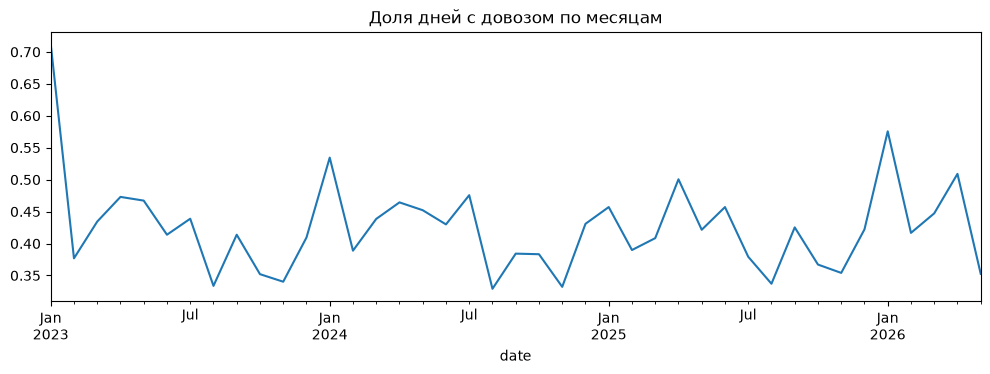

In [14]:
# Довозы: дни, когда утреннего плана не хватило
m["short"] = m["extra_cash_load_uzs"] > 0
print(f"дней с довозом: {m['short'].mean():.2%}")
print(f"дней с нулевой инкассацией: {(m['cash_collected_eod_uzs'] == 0).mean():.2%}")

print("\nСредние в обычные дни и в дни с довозом:")
display(m.groupby("short")[["y", "planned_cash_load_uzs", "extra_cash_load_uzs",
                            "cash_collected_eod_uzs", "plan_to_y"]].mean())

print("Доля дней с довозом по дню недели:")
print(m.groupby(m["date"].dt.day_of_week)["short"].mean().round(3).to_string())

short_m = m.set_index("date")["short"].resample("MS").mean()
short_m.plot(title="Доля дней с довозом по месяцам")
plt.show()

**Вывод.**
- **План есть на весь период прогноза** (59 филиалов x 30 дней). Довоз и инкассация в будущем пустые, как и должно быть:
  утечки будущего нет.
- **План - это прогноз банка с запасом ~10%.** Корреляция со снятиями 0,88 (внутри филиала 0,76), медиана план/факт 1,10.
  Сильный признак и бейзлайн, который модель должна побить.
- **Баланс сходится:** план + довоз - инкассация = снятия, медиана отношения 1,001, у 90% дней отклонение в пределах 2-4%.
  Взносы в балансе не участвуют. Значит, cash_ops - независимая проверка журнала транзакций.
- **Довоз был в 42% дней.** В такие дни план в среднем 1,11 млрд при спросе 1,25 млрд. Это та самая дорогая ошибка
  из условия задачи: нынешний план недовозит почти через день. В январе довозов заметно больше.
- **Нулевой инкассации нет.** Наличные ни разу не заканчивались полностью, поэтому записанные снятия равны спросу,
  поправка на цензурирование не нужна.

## 5. Новые и нестандартные филиалы

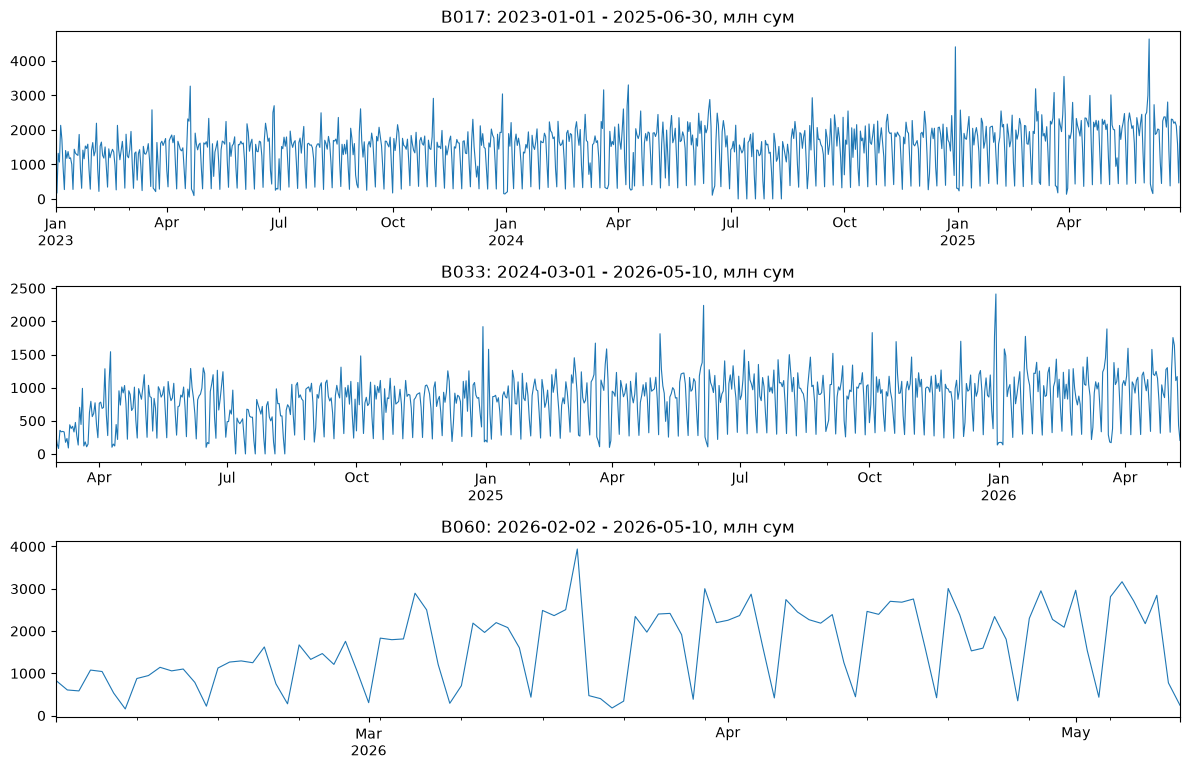

In [15]:
odd = list(span[~span["in_template"]].index) + list(span.sort_values("first").tail(2).index)
odd = list(dict.fromkeys(odd))  # без повторов
fig, axes = plt.subplots(len(odd), 1, figsize=(12, 2.6 * len(odd)), squeeze=False)
for ax, b in zip(axes[:, 0], odd):
    s = target[target["branch_id"] == b].set_index("date")["y"] / 1e6
    s.plot(ax=ax, lw=0.8)
    ax.set(title=f"{b}: {span.loc[b, 'first'].date()} - {span.loc[b, 'last'].date()}, млн сум", xlabel="")
plt.tight_layout()
plt.show()

In [16]:
# Закрытие филиала: ушли ли его клиенты к соседям по региону?
# Сравниваем средние снятия за 8 недель до и 8 недель после закрытия.
for b, r in span[~span["in_template"]].iterrows():
    before = full[(full["date"] > r["last"] - pd.Timedelta(days=56)) & (full["date"] <= r["last"])]
    after = full[(full["date"] > r["last"]) & (full["date"] <= r["last"] + pd.Timedelta(days=56))]
    chg = (after.groupby("branch_id")["y"].mean() / before.groupby("branch_id")["y"].mean()).dropna()
    chg = chg.to_frame("после / до").join(branches.set_index("branch_id")[["region"]])
    same = chg["region"] == r["region"]
    print(f"{b} ({r['region']}) закрыт после {r['last'].date()}")
    print(f"  соседи по региону: медиана {chg.loc[same, 'после / до'].median():.3f}")
    print(f"  остальные филиалы: медиана {chg.loc[~same, 'после / до'].median():.3f}")
    display(chg[same].sort_values("после / до", ascending=False))

B017 (Toshkent vil.) закрыт после 2025-06-30
  соседи по региону: медиана 1.026
  остальные филиалы: медиана 1.037


,после / до,region
branch_id,,
B015,1.080,Toshkent vil.
B016,1.060,Toshkent vil.
B018,0.991,Toshkent vil.
B019,0.982,Toshkent vil.


**Вывод.**
- **Новые филиалы разгоняются.** B060 вырос с ~0,8 до 2,5–3 млрд сум в день за два месяца и с апреля 2026 стабилен. B033 вышел на уровень примерно за пять недель.
- **Для B060 уровень берём из последних недель:** период разгона занижает оценку.
- **Закрытие B017 на соседей не повлияло:** +2,6% у филиалов региона против +3,7% у остальных.

## 6. Проверка аномалий через баланс наличных

Раз баланс `план + довоз - инкассация = снятия` сходится, им можно проверить журнал транзакций:
если наличные из филиала ушли, а снятий в журнале меньше, значит, часть операций не записана.

In [17]:
# доля оттока наличных, которой нет в журнале транзакций
m["unlogged"] = 1 - m["y"] / m["net_load"].where(m["net_load"] > 0)
m["flag"] = m["unlogged"].abs() > 0.15

print(f"дней с расхождением больше 15%: {m['flag'].sum()} ({m['flag'].mean():.2%})")
by_month = m.set_index("date").resample("MS").agg(
    дней_с_расхождением=("flag", "sum"), средняя_доля_без_записи=("unlogged", "mean")
)
display(by_month[by_month["дней_с_расхождением"] > 0])

flagged_days = m[m["flag"]].groupby("date")["branch_id"].nunique()
print("Дни, когда расхождение сразу в 10+ филиалах:")
big = flagged_days[flagged_days >= 10]
print(f"  {len(big)} дней, с {big.index.min().date() if len(big) else '-'} по {big.index.max().date() if len(big) else '-'}")

дней с расхождением больше 15%: 2788 (3.98%)


,дней_с_расхождением,средняя_доля_без_записи
date,,
2023-03-01,2,-0.000
2023-06-01,7,-0.001
2023-12-01,1,-0.000
2024-01-01,11,-0.001
2024-04-01,5,-0.001
2024-06-01,12,0.001
2024-07-01,1809,0.375
2024-08-01,881,0.183
2024-12-01,4,0.000


Дни, когда расхождение сразу в 10+ филиалах:
  46 дней, с 2024-07-01 по 2024-08-15


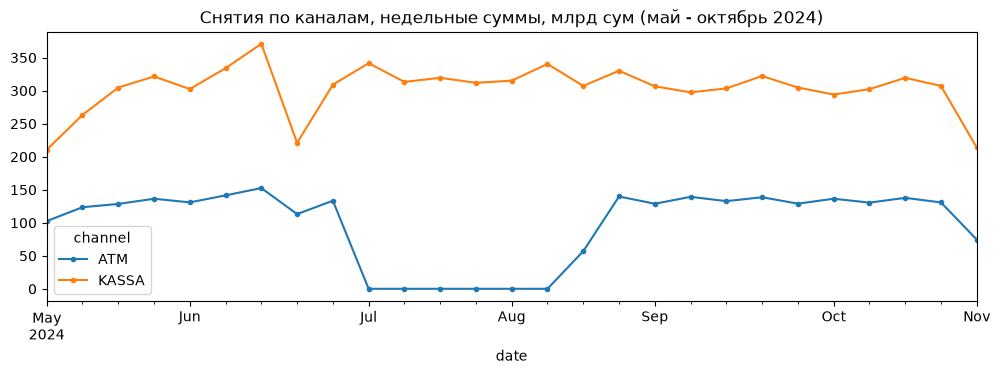

channel,ATM,KASSA
date,,
2024-05-05,102.600,210.600
2024-05-12,123.600,263.200
2024-05-19,128.500,304.700
2024-05-26,136.400,321.500
2024-06-02,130.900,302.400
2024-06-09,141.500,334.000
2024-06-16,152.600,370.900
2024-06-23,113.200,221.000
2024-06-30,133.400,309.100


In [18]:
# Провал 2024 года по каналам: недельные суммы снятий, млрд сум
w24 = w[w["date"].between("2024-05-01", "2024-10-31")]
weekly = w24.groupby([pd.Grouper(key="date", freq="W-SUN"), "channel"])["amount_uzs"].sum().unstack() / 1e9
weekly.plot(marker="o", ms=3, title="Снятия по каналам, недельные суммы, млрд сум (май - октябрь 2024)")
plt.show()
display(weekly.round(1))

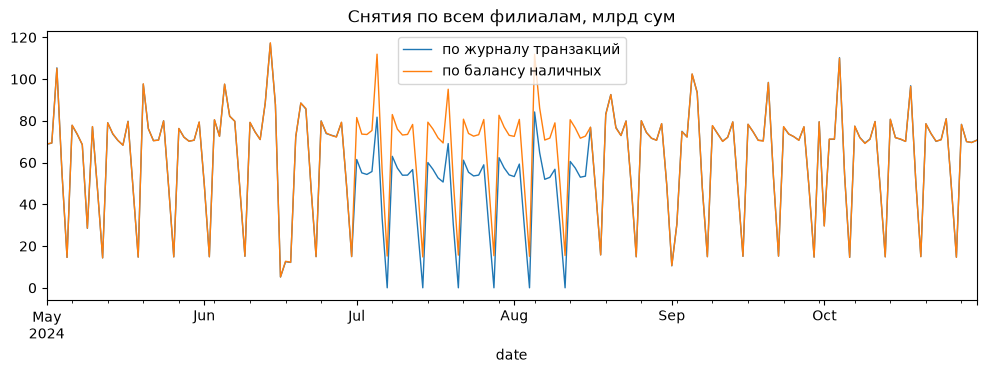

In [19]:
# Тот же период: снятия по журналу и по балансу наличных
sub = m[m["date"].between("2024-05-01", "2024-10-31")].groupby("date")[["y", "net_load"]].sum() / 1e9
sub.columns = ["по журналу транзакций", "по балансу наличных"]
sub.plot(lw=1, title="Снятия по всем филиалам, млрд сум")
plt.show()

In [20]:
# Неделя в Xorazm: что показывает cash_ops за дни без транзакций
miss_rows = miss.merge(cash, on=["branch_id", "date"], how="left")
display(miss_rows.sort_values(["branch_id", "date"]))

,branch_id,date,y,planned_cash_load_uzs,extra_cash_load_uzs,cash_collected_eod_uzs
0,B051,2025-11-10,NaN,990000000,0.000,"76,359,000.000"
1,B051,2025-11-11,NaN,890000000,0.000,"77,271,000.000"
2,B051,2025-11-12,NaN,860000000,"30,000,000.000","64,194,000.000"
3,B051,2025-11-13,NaN,890000000,0.000,"340,161,000.000"
4,B051,2025-11-14,NaN,950000000,0.000,"154,001,000.000"
5,B052,2025-11-10,NaN,1780000000,"50,000,000.000","111,937,000.000"
6,B052,2025-11-11,NaN,1630000000,0.000,"171,926,000.000"
7,B052,2025-11-12,NaN,1760000000,0.000,"291,228,000.000"
8,B052,2025-11-13,NaN,1630000000,0.000,"381,113,000.000"
9,B052,2025-11-14,NaN,1770000000,"120,000,000.000","87,297,000.000"


In [21]:
# Прочие дни с расхождением (вне основного периода сбоя)
other = m[m["flag"] & ~m["date"].isin(big.index)]
print("строк:", len(other))
display(other.sort_values("unlogged", key=abs, ascending=False)
        [["branch_id", "date", "y", "net_load", "unlogged"]].head(20))

строк: 98


,branch_id,date,y,net_load,unlogged
64058,B053,2025-11-11,0.000,"2,398,734,000.000",1.000
64057,B053,2025-11-10,0.000,"2,464,172,000.000",1.000
65287,B054,2025-11-14,0.000,"922,195,000.000",1.000
65286,B054,2025-11-13,0.000,"768,539,000.000",1.000
65284,B054,2025-11-11,0.000,"875,742,000.000",1.000
65285,B054,2025-11-12,0.000,"828,801,000.000",1.000
62832,B052,2025-11-11,0.000,"1,458,074,000.000",1.000
62833,B052,2025-11-12,0.000,"1,468,772,000.000",1.000
62831,B052,2025-11-10,0.000,"1,718,063,000.000",1.000
61609,B051,2025-11-14,0.000,"795,999,000.000",1.000


**Вывод.** Найдены два периода, когда наличные из филиалов уходили, а операций в журнале нет:

1. **1 июля – 15 августа 2024, все филиалы.** Пропали записи банкоматов, касса не затронута.
2. **10–14 ноября 2025, четыре филиала Xorazm (B051–B054).** Пропали все записи.

Баланс наличных в эти дни идёт на обычном уровне, значит, это потеря данных, а не падение спроса.

**Решение:** за эти периоды снятия восстанавливаем по балансу: `план + довоз − инкассация`.

Остальные расхождения единичны (~80 дней за 3,4 года), их не трогаем.**Вывод:** _(заполнить после запуска)_
- _Провал июля-августа 2024: если по каналам видно, что пропадает ATM, а баланс наличных в эти дни идёт на прежнем уровне,
  то это потеря записей банкоматов в журнале, а не падение спроса. Тогда за этот период снятия берём по балансу
  (или исключаем период из обучения)._
- _Xorazm, 10-14 ноября 2025: если в cash_ops за эти дни есть загрузка и инкассация, филиалы работали и потеряны только записи;
  если строк нет или всё по нулям, филиалы были закрыты._